In [3]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
import csv
import pandas as pd
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torch_optimizer import Lookahead
from tqdm import tqdm
from torchvision.transforms import v2 as transforms
from torch.utils.data import WeightedRandomSampler
import albumentations as A
from albumentations.pytorch import ToTensorV2
#from ranger21 import Ranger21
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from lion_pytorch import Lion
#!pip install torchview
from torchview import draw_graph
import optuna
import gc

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
# !pkill -f tensorboard
# %load_ext tensorboard
# !mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
from io import BytesIO
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu130
Device: cuda


### Loading Image–Mask Pairs from Image IDs

This section loads image patches and their corresponding masks based on a predefined list of image IDs.  
The function assumes a consistent naming convention between image and mask files, allowing automatic pairing.

**Key steps:**
- Iterates through all files in the specified folder
- Loads the image patch and its corresponding mask
- Converts the mask to grayscale 


**Output:**
- A list of image patches
- A list of corresponding mask patches
- The associated image IDs



In [4]:
def load_images_from_ids(folder, image_ids):
    """
    Load patches corresponding to a list of image IDs.
    Assumes patch files are named like img_XXXX_pY.png
    """
    images = []
    masks =  []
    images_id = []  

    for file in tqdm(os.listdir(folder)):
        # Extract image id from patch filename
        if file in image_ids and file.startswith('img_'):

            path = os.path.join(folder, file)
            path_mask = path.replace('img_','mask_')
            img = cv2.imread(path)
            mask = cv2.imread(path_mask)
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
            if img is None:
                continue

            images.append(img)
            masks.append(mask)
            images_id.append(file)  # temporarily store img_id, will map to label later

    return images, masks, images_id



### Label Preparation and Patch-Level Dataset Assembly

This section prepares class labels and constructs the final dataset used for training and validation.

**Label processing:**
- Loads the original image-level labels from a CSV file
- Builds a dictionary to quickly associate each image ID with its class label

**Patch loading:**
- Loads image patches and corresponding masks based on the available image IDs


**Final checks:**
- Reports class distribution to assess dataset balance
- Computes the number of target classes for training setup



In [ ]:
# load the train labels
train_labels_df = pd.read_csv("train_labels.csv")  # labels per original image
# Map string labels to integers and replace on the dataframe
label_mapping = {
    "Luminal A": 0,
    "Luminal B": 1,
    "HER2(+)": 2,
    "Triple negative": 3
}
train_labels_df["label"] = train_labels_df["label"].replace(label_mapping)


# Split images into train/val sets
image_ids = train_labels_df['sample_index'].astype(str).tolist() 
labels_dict = dict(zip(train_labels_df['sample_index'].astype(str), train_labels_df['label']))

folder_train_path = 'train_data_NOSHREK/'

# Call the funciton to load the images, masks and corresponding IDS
X_all, X_all_mask, all_patch_image_ids = load_images_from_ids(folder_train_path, image_ids)
X_all = np.array(X_all, dtype=object)  
X_all_mask = np.array(X_all_mask, dtype=object)

# Map image IDs of patches to labels
y_all = np.array([labels_dict[i] for i in all_patch_image_ids])


print(f"Images: {len(X_all)}, Masks: {len(X_all_mask)}")
print("Training labels distribution: ", np.unique(y_all, return_counts=True))
num_classes = np.unique(y_all).size
print(f"Number of classes: {num_classes}") 


100%|██████████| 1162/1162 [00:16<00:00, 70.63it/s]

Images: 581, Masks: 581
Training labels distribution:  (array([0, 1, 2, 3]), array([158, 204, 150,  69]))
Number of classes: 4


In [ ]:
# Number Of classes
num_classes = np.unique(y_all).size
print(f"Number of classes: {num_classes}")

Number of classes: 4


### PatchDataset: Patch-Based Image–Mask Dataset

This class defines a custom PyTorch dataset for patch-based learning using paired images and masks.  
Each sample is decomposed into multiple patches during computation, enabling fine-grained training while preserving image-level labels.

**Key features:**
- Extracts fixed-size patches using a sliding window
- Uses the mask to guide patch selection, filtering out background regions
- Limits the number of patches per image to control memory usage

**Augmentation:**
- Geometric augmentations are applied synchronously to image and mask
- Photometric augmentations are applied only to the RGB image
- ImageNet normalization for transfer learning with pretrained backbones

**Output:**
- A variable number of image patches and corresponding mask patches per sample
- Image-level labels are propagated to all extracted patches



In [ ]:
# ImageNet normalization statistics 
IMAGENET_MEAN = [0.485, 0.456, 0.406] 
IMAGENET_STD = [0.229, 0.224, 0.225]


class PatchDataset(torch.utils.data.Dataset):

    def __init__(self, images, masks, labels=None,
                 geometric_augmentation=None, fotometric_augmentation=None, normalize_imagenet=False):

        self.images = images          # (N, H, W, 3)
        self.masks = masks            # (N, H, W)
        self.labels = torch.from_numpy(labels).long() if labels is not None else None

        self.geometric_augmentation = geometric_augmentation
        self.fotometric_augmentation = fotometric_augmentation

        if normalize_imagenet:
            self.normalize = transforms.Normalize(
                mean=IMAGENET_MEAN, std=IMAGENET_STD
            )
        else:
            self.normalize = None

    def __len__(self):
        return len(self.images)

    # EXTRACT PATCHES (we use masks to choose where cropping)
    def extract_patches(self, image, mask,
                        patch_size=224, stride=224,
                        mask_thresh=0.02, max_patches=20):

        img_patches = []
        mask_patches = []

        h, w = mask.shape
        total_pixels = patch_size * patch_size

        for y in range(0, h - patch_size + 1, stride):
            for x in range(0, w - patch_size + 1, stride):

                mask_patch = mask[y:y+patch_size, x:x+patch_size]
                
                # Counting the black point to decide if is a good patch
                if mask_patch.sum() < mask_thresh * total_pixels:
                    continue
                img_patch = image[y:y+patch_size, x:x+patch_size]           # Cropped image

                if self.geometric_augmentation:
                    augmentation = self.geometric_augmentation(image=img_patch, mask=mask_patch)
                    img_patch = augmentation["image"]
                    mask_patch = augmentation["mask"]

                if self.fotometric_augmentation:
                    augmentation = self.fotometric_augmentation(image=img_patch)
                    img_patch = augmentation["image"]

                # to Tensor
                img_tensor = torch.from_numpy(img_patch).permute(2,0,1).float() / 255.0
                mask_tensor = torch.from_numpy(mask_patch).unsqueeze(0).float()  # (1,H,W)

                # Normalize RGB
                if self.normalize:
                    img_tensor = self.normalize(img_tensor)

                mask_tensor = mask_tensor.clamp(0, 1)

                img_patches.append(img_tensor)
                mask_patches.append(mask_tensor)

        if len(img_patches) == 0:
            return None, None

        # Return a limited number of patches
        if len(img_patches) > max_patches:
            idxs = random.sample(range(len(img_patches)), max_patches)
            img_patches = [img_patches[i] for i in idxs]
            mask_patches = [mask_patches[i] for i in idxs]

        return (
            torch.stack(img_patches, dim=0),   
            torch.stack(mask_patches, dim=0)   
        )

    def __getitem__(self, idx):

        image = self.images[idx].copy()
        mask  = self.masks[idx].copy()

        img_patches, mask_patches = self.extract_patches(image, mask)

        if img_patches is None:
            # dummy patch (caso raro)
            img_patches = torch.zeros((1, 3, 224, 224))
            mask_patches = torch.zeros((1, 1, 224, 224))

        # Addded for the test data
        if self.labels is None:
            return img_patches, mask_patches
        else:
            return img_patches, mask_patches, self.labels[idx]


### Custom Collate Function for Patch-Based Training

This custom collate function prepares batches for patch-based training where each image may produce a variable number of patches.

In [ ]:
def collate_train(batch):
    """
    batch = list of (img_patches, mask_patches, label)

    img_patches  : Tensor [N_i, 3, H, W]
    mask_patches : Tensor [N_i, 1, H, W]
    label        : scalar tensor
    """

    img_patches_list = []
    mask_patches_list = []
    labels_list = []

    for img_patches, mask_patches, label in batch:
        img_patches_list.append(img_patches)     
        mask_patches_list.append(mask_patches)   
        labels_list.append(label)

    labels = torch.stack(labels_list)  

    return img_patches_list, mask_patches_list, labels


In [9]:
def make_loader(ds, batch_size, shuffle, drop_last, collate_fn):
    """Create a PyTorch DataLoader with optimized settings."""
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        sampler=None,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,
        collate_fn=collate_fn
    )

In [10]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []


    for img_patches_list, mask_patches_list, labels in train_loader:
        """
        img_patches_list  : list of length B, each [N_i, 3, H, W]
        mask_patches_list : list of length B, each [N_i, 1, H, W]
        labels            : [B]
        """

        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)

        image_logits = []  # aggregated logits per image

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            for img_patches, mask_patches in zip(img_patches_list, mask_patches_list):
                img_patches = img_patches.to(device)     # [N_i,3,H,W]
                mask_patches = mask_patches.to(device)   # [N_i,1,H,W]

                # Patch-level inference
                logits_patches = model(img_patches, mask_patches)  # [N_i, num_classes]

                # IMAGE-LEVEL aggregation (MIL mean pooling)
                logits_image = logits_patches.mean(dim=0)  # [num_classes]
                image_logits.append(logits_image)

            image_logits = torch.stack(image_logits)  # [B, num_classes]

            loss = criterion(image_logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * labels.size(0)

        predictions = image_logits.argmax(dim=1)
        all_predictions.append(predictions.detach().cpu().numpy())
        all_targets.append(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average="weighted"
    )

    return epoch_loss, epoch_f1

def validate_one_epoch(model, val_loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for img_patches_list, mask_patches_list, labels in val_loader:
            """
            img_patches_list  : list of length B, each [N_i, 3, H, W]
            mask_patches_list : list of length B, each [N_i, 1, H, W]
            labels            : [B]
            """

            labels = labels.to(device)
            image_logits = []

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                for img_patches, mask_patches in zip(img_patches_list, mask_patches_list):
                    img_patches = img_patches.to(device)
                    mask_patches = mask_patches.to(device)

                    # Patch-level inference
                    logits_patches = model(
                        img_patches, mask_patches
                    )  # [N_i, num_classes]

                    # IMAGE-LEVEL aggregation (MIL mean pooling)
                    logits_image = logits_patches.mean(dim=0)
                    image_logits.append(logits_image)

                image_logits = torch.stack(image_logits)  # [B, num_classes]

                loss = criterion(image_logits, labels)

            running_loss += loss.item() * labels.size(0)

            predictions = image_logits.argmax(dim=1)
            all_predictions.append(predictions.detach().cpu().numpy())
            all_targets.append(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average="weighted"
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=1, experiment_name=""):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if writer is not None:
            writer.add_scalar('Loss/Training', train_loss, epoch)
            writer.add_scalar('Loss/Validation', val_loss, epoch)
            writer.add_scalar('F1/Training', train_f1, epoch)
            writer.add_scalar('F1/Validation', val_f1, epoch)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models_Optn/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models_Optn/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), "models_Optn/"+experiment_name+'_model.pt')

    if writer is not None:
        writer.close()

    return model, training_history

# Dual branch ConvNeXt architecture

This model implements a **dual-branch architecture** designed to jointly exploit **visual appearance** and **spatial mask information** for image patch classification. The two information streams are processed independently and then fused at the feature level, allowing the model to integrate complementary cues before making a prediction.

### RGB Branch (Transfer Learning)

The primary branch processes the RGB image patches using a **pretrained ConvNeXt backbone**.

Key characteristics of this branch:
- The backbone is **frozen** during training to preserve pretrained features and reduce overfitting. ConvNeXt has a very large number of parameters, and training it from scratch would not have been feasible given the size of our dataset.

- The output of the backbone is globally pooled to produce a **compact, high-level feature vector** representing the visual content of the patch.

This branch captures **texture, shape, and semantic patterns** present in the RGB data.


### Mask Branch: Learning Spatial and Structural Cues

The second branch processes a **single-channel mask** associated with each image patch. Unlike the RGB branch, this pathway is intentionally lightweight and shallow.

Its role is to:
- encode **spatial priors** and structural information contained in the mask,
- summarize the presence, distribution, and geometry of relevant regions,
- and provide complementary context that may not be easily inferred from RGB information alone.

By applying convolutional layers followed by global pooling, this branch transforms the mask into a **low-dimensional embedding** that emphasizes global structure rather than fine-grained details.


### Feature Fusion Strategy

After independent processing, the RGB and mask features are **concatenated** to form a joint representation. This fusion strategy allows the classifier to:
- combine appearance-based and structure-based information,
- learn interactions between visual patterns and spatial constraints,
- and make decisions based on a richer, multimodal feature space.

### Classification Head

The fused feature vector is passed through a compact classification module:
- intermediate layers enable **feature interaction and refinement**,
- dropout provides **regularization**, reducing overfitting,
- the final layer maps the learned representation to the target classes.

This design balances **model expressiveness** with **training stability**, which is particularly important in patch-based and data-limited settings.




In [11]:
class LayerNorm2d(nn.Module):
    def __init__(self, num_channels, eps=1e-6):
        super().__init__()
        self.norm = nn.LayerNorm(num_channels, eps=eps)

    def forward(self, x):
        # x: [batch, channels, height, width]
        # transpose to [batch, height, width, channels] for LayerNorm
        x = x.permute(0, 2, 3, 1)
        x = self.norm(x)
        # back to [batch, channels, height, width]
        x = x.permute(0, 3, 1, 2)
        return x

In [ ]:
class ConvNextTransferLearning(nn.Module):
    def __init__(self, num_classes, dropout_rate, freeze_backbone=True):
        super().__init__()

        # RGB branch
        self.rgb_net = torchvision.models.convnext_tiny(
            weights=torchvision.models.ConvNeXt_Tiny_Weights.DEFAULT
        )

        if freeze_backbone:
            for p in self.rgb_net.features.parameters():
                p.requires_grad = False

        self.rgb_feat_dim = self.rgb_net.classifier[-1].in_features
        self.rgb_net.classifier = nn.Identity()
        self.rgb_pool = nn.AdaptiveAvgPool2d(1)

        # Mask branch
        self.mask_net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(16, 16)
        )

        # Fusion
        self.classifier = nn.Sequential(
            nn.Linear(self.rgb_feat_dim + 16, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate),
            nn.Linear(64, num_classes)
        )

    def forward(self, image, mask):
        feat_rgb = self.rgb_net(image)     
        feat_rgb = self.rgb_pool(feat_rgb)  
        feat_rgb = feat_rgb.flatten(1)      

        feat_mask = self.mask_net(mask)   

        feat = torch.cat([feat_rgb, feat_mask], dim=1)
        return self.classifier(feat)


### Augmentation using albumentations
This is our augmentation pipeline, possible patches generation can be viewed in `visualizePatches.ipynb`

In [14]:
# Define augmentation for training
geometric_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.10, rotate_limit=15, border_mode=0, p=0.5),  # constant padding (black)
    #A.RandomResizedCrop(height=224, width=224, scale=(0.9, 1), ratio=(0.9, 1), p=0.5),
    A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5, border_mode=0, p=0.2)
])

fotometric_augmentation = A.Compose([
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02, p=0.5),
    A.GaussianBlur(blur_limit=(3, 7), p=0.3),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
    A.Sharpen(alpha=(0.1, 0.3), lightness=(0.7, 1.0), p=0.2),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.2),
    A.ToGray(p=0.05),
])




In [ ]:
# Setup training
experiment_name = "transfer_learning"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# K-Fold CV
This function implements a full K-fold cross-validation training pipeline for patch-based image classification.

**Cross-validation setup:**
- Uses stratified K-fold splitting to preserve class balance across folds
- Trains and validates a separate model for each fold
- Aggregates performance metrics across splits for robust evaluation

**Optimization and logging:**
- Uses the Lion optimizer with decoupled weight decay
- Saves checkpoints and logs metrics per fold



In [ ]:
def k_fold_training(X_all, X_mask_all, y_all, num_classes, fotometric_augmentation, geometric_augmentation, batch_size, epochs, patience, dropout_rate, scaler, device, 
                    writer, learning_rate, weight_decay, verbose=1, K=5, trial=None):

    skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}
    fold_best_f1 = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_all), start=1):
        print(f"\n==================== FOLD {fold}/{K} ====================\n")
        
        # Split
        X_train, X_val = X_all[train_idx], X_all[val_idx]
        X_mask_train, X_mask_val = X_mask_all[train_idx], X_mask_all[val_idx]
        y_train, y_val = y_all[train_idx], y_all[val_idx]

        # Dataset
        train_ds = PatchDataset(X_train, X_mask_train, y_train, geometric_augmentation=geometric_augmentation, fotometric_augmentation=fotometric_augmentation, normalize_imagenet=True)
        val_ds = PatchDataset(X_val, X_mask_val, y_val, geometric_augmentation=None, fotometric_augmentation=None, normalize_imagenet=True)
        
        # Loader
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False, collate_fn=collate_train)
        val_loader = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False, collate_fn=collate_train)

        # Model
        model = ConvNextTransferLearning(
            num_classes=num_classes,
            dropout_rate=dropout_rate,
            freeze_backbone=True
        ).to(device)
        

        class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
        class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
        criterion = nn.CrossEntropyLoss(weight=class_weights)

        # optimizer fresh
        optimizer = Lion(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate, weight_decay=weight_decay)

        experiment_name = f"LR_{learning_rate}_DR_{dropout_rate}_BS_{batch_size}_WD_{weight_decay}"
        # Create directory for model checkpoints
        os.makedirs(f"models_Optn/{experiment_name}", exist_ok=True)

        # Train
        _, history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=device,
            writer=writer,
            verbose=verbose,
            experiment_name=experiment_name+"/fold_"+str(fold),
            patience=patience
        )

        # Store results for this split
        fold_losses[f"split_{fold}"] = history['val_loss']
        fold_metrics[f"split_{fold}"] = history['val_f1']
        best_scores[f"split_{fold}"] = max(history['val_f1'])
        fold_best_f1.append(max(history['val_f1']))
        if trial is not None:
            current_score = best_scores[f"split_{fold}"]

            # Report for ooptuna
            trial.report(current_score, step=fold)

            if trial.should_prune():
                print(f"Trial pruned at fold {fold}")
                raise optuna.exceptions.TrialPruned()


    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print("\n==================== K-FOLD SUMMARY ====================")
        print(f"Best score: {best_scores['mean']:.4f}±{best_scores['std']:.4f}")

    if trial is not None:
        trial.set_user_attr("f1_per_split", fold_best_f1)


    return fold_losses, fold_metrics, best_scores



### Optuna integration


We have used optuna to improve the efficiency of the cross validation to find the best hyperparameters, the function objective and study are used to create the configurations.

In [24]:
def run_optuna_kfold(X_all, X_mask_all, y_all, num_classes, fotometric_augmentation, geometric_augmentation, epochs, patience, scaler, device, writer, K, n_trials=10, verbose=0):
    """
    Optuna wrapper che ottimizza gli hyperparametri
    usando k-fold cross validation.
    """

    def objective(trial):

        # HyperParm tuning
        dropout_rate = trial.suggest_float("dropout_rate", 0.35, 0.5)
        learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-4, log=True)
        weight_decay = trial.suggest_float("weight_decay", 1e-3, 1e-2, log=True)
        batch_size = trial.suggest_categorical("batch_size", [2, 4, 8, 16])

        print("\n================ PARAMETERS ================")
        print(f"DR: {dropout_rate:.2f} \t LR: {learning_rate:.5f}\t WD: {weight_decay:.5f} \t BS: {batch_size}")
        print("============================================\n")

        # Start K-FOLD
        _, _, fold_scores = k_fold_training(
            X_all=X_all,
            X_mask_all=X_mask_all,
            y_all=y_all,
            num_classes=num_classes,
            fotometric_augmentation=fotometric_augmentation,
            geometric_augmentation=geometric_augmentation,
            batch_size=batch_size,
            epochs=epochs,
            patience=patience,
            scaler=scaler,
            device=device,
            writer=None,
            trial=trial,     
            verbose=verbose,
            dropout_rate=dropout_rate,
            learning_rate=learning_rate,
            weight_decay=weight_decay,
            K=K
        )

        mean_f1 = fold_scores["mean"]
        
        #Empty cache
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        return mean_f1

    # Create study
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=3,
            n_warmup_steps=3
        )
    )

    study.optimize(objective, n_trials=n_trials)

    print("\n================ OPTUNA SUMMARY ================")
    print("Best F1:", study.best_value)
    print("Best params:")
    for k, v in study.best_params.items():
        print(f"  {k}: {v}")

    return study


In [18]:
EPOCHS = 200
PATIENCE = 17
K_FOLD = 5

In [ ]:
%%time
study = run_optuna_kfold( 
    X_all=X_all,
    X_mask_all=X_all_mask,
    y_all=y_all,
    num_classes=num_classes,
    geometric_augmentation=geometric_augmentation,
    fotometric_augmentation=fotometric_augmentation,
    epochs=EPOCHS,
    patience=PATIENCE,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    K=K_FOLD
)

best_params = study.best_params

print(best_params, type(best_params))

Unfortunately, the training logs were lost after starting a new run, we are deeply sorry for that. We were only able to save the box plot.
It was not possible to run a new training session because the previous one took approximately 23 hours :(


## Plot Result
This section visualizes the cross-validation performance of the top Optuna trials using boxplots.
This analysis supports informed hyperparameter selection beyond single-score optimization.

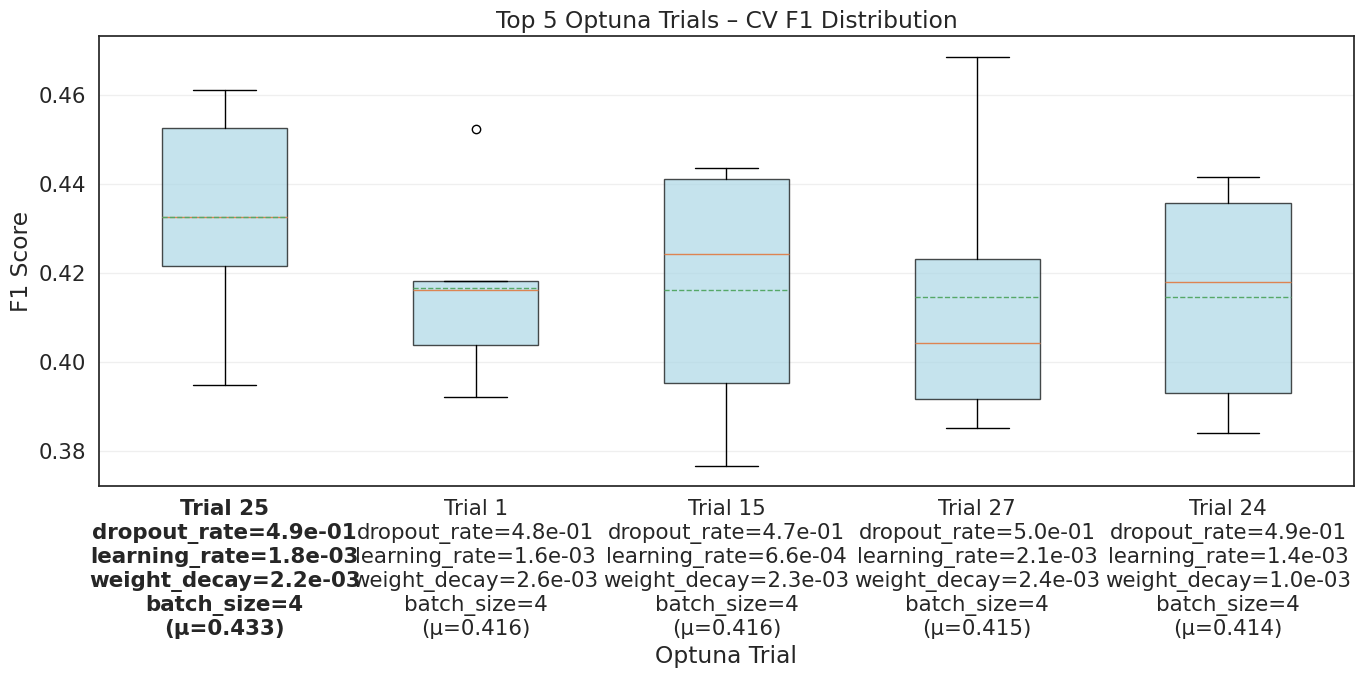

In [ ]:

def plot_top_optuna_trials_boxplot(
    study,
    top_n=5,
    figsize=(14, 7)
):
    import numpy as np
    import matplotlib.pyplot as plt
    import optuna

    completed_trials = [
        t for t in study.trials
        if t.state == optuna.trial.TrialState.COMPLETE
        and "f1_per_split" in t.user_attrs
    ]

    if len(completed_trials) == 0:
        print("No completed trials with CV data found.")
        return

    completed_trials.sort(key=lambda t: t.value, reverse=True)
    top_trials = completed_trials[:top_n]

    boxplot_data = []
    labels = []

    for trial in top_trials:
        f1_splits = trial.user_attrs["f1_per_split"]
        boxplot_data.append(f1_splits)

        
        params = []
        for k, v in trial.params.items():
            if isinstance(v, float):
                params.append(f"{k}={v:.1e}")
            else:
                params.append(f"{k}={v}")

        label = (
            f"Trial {trial.number}\n"
            + "\n".join(params)
            + f"\n(μ={trial.value:.3f})"
        )

        labels.append(label)

    fig, ax = plt.subplots(figsize=figsize)

    bp = ax.boxplot(
        boxplot_data,
        labels=labels,
        patch_artist=True,
        showmeans=True,
        meanline=True
    )

    for patch in bp["boxes"]:
        patch.set_facecolor("lightblue")
        patch.set_alpha(0.7)

    # The best is highlighted
    ax.get_xticklabels()[0].set_fontweight("bold")

    ax.set_ylabel("F1 Score")
    ax.set_xlabel("Optuna Trial")
    ax.set_title(f"Top {len(top_trials)} Optuna Trials – CV F1 Distribution")
    ax.grid(alpha=0.3, axis="y")

    plt.tight_layout()
    plt.show()

plot_top_optuna_trials_boxplot(study,top_n=5)

# Fine Tuning

In the fine-tuning phase, we reused the same model architecture and training pipeline, modifying only the **weight-freezing strategy**. Instead of keeping the entire backbone frozen, we progressively **unfroze selected parts of the network**, allowing a subset of pretrained weights to be updated during training.

### Progressive Unfreezing Strategy

To control training stability, we adopted a **gradual unfreezing strategy**:
- initially unfreezing only the top (later) layers of the backbone,
- then progressively allowing more layers to be trained.

### Observed Behavior

As more parameters were unfrozen, we observed:
- faster convergence on the training set,
- a growing gap between training and validation performance,
- and increasingly unstable validation metrics.

These signals indicate **overfitting** (some of our submission demonstrated that)

### Conclusion

Given the **limited size and imbalance of our dataset**, fine tuning a large backbone such as ConvNeXt proved to be of limited benefit.


In [29]:
print(best_params)
best_param_str = f"LR_{best_params['learning_rate']}_DR_{best_params['dropout_rate']}_BS_{best_params['batch_size']}_WD_{best_params['weight_decay']}"
print(best_param_str)


{'learning_rate': 8.927180304353642e-05, 'dropout_rate': 0.40618101782710436, 'batch_size': 2, 'weight_decay': 0.00539503096667023}
LR_8.927180304353642e-05_DR_0.40618101782710436_BS_2_WD_0.00539503096667023


The following code, loads the model with the `best_params` obtained with optuna. 

In [ ]:
def model_def(fold, num_classes, dropout_rate, best_params_str, freeze_backbone=False):
    ft_model = ConvNextTransferLearning(num_classes, dropout_rate, freeze_backbone=freeze_backbone).to(device)
    ft_model.load_state_dict(torch.load(f"models_Optn/{best_params_str}/fold_{fold}_model.pt"))


    # Strategy: Freeze everything first, then unfreeze the last few blocks
    for param in ft_model.parameters():
        param.requires_grad = False

    # The classifier is always trainable
    for param in ft_model.classifier.parameters():
        param.requires_grad = True

    # The mask branch is always trainable
    for param in ft_model.mask_net.parameters():
        param.requires_grad = True

    # unlocking the last blocks of the backbone
    last_block = ft_model.rgb_net.features[7][-1].block
    for param in last_block[0].parameters():
        param.requires_grad = True
    for param in last_block[2].parameters():
        param.requires_grad = True
    

    return ft_model

In [55]:
def k_fold_training_FT(X_all, X_mask_all, y_all, num_classes, geometric_augmentation, fotometric_augmentation, batch_size, epochs, patience, dropout_rate, scaler, device, 
                    writer, learning_rate, weight_decay, best_param_str, verbose=1, K=5):

    skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

    fold_f1s = []
    fold_models = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_all), start=1):
        print(f"\n==================== FOLD {fold}/{K} ====================\n")
        
        # Split
        X_train, X_val = X_all[train_idx], X_all[val_idx]
        X_mask_train, X_mask_val = X_mask_all[train_idx], X_mask_all[val_idx]
        y_train, y_val = y_all[train_idx], y_all[val_idx]


        # cls_weights = torch.from_numpy(compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train))
        # weights = cls_weights[y_train]
        # sampler = WeightedRandomSampler(weights, len(y_train), replacement=True)

        # Dataset# Dataset
        train_ds = PatchDataset(X_train, X_mask_train, y_train, geometric_augmentation=geometric_augmentation, fotometric_augmentation=fotometric_augmentation, normalize_imagenet=True)
        val_ds = PatchDataset(X_val, X_mask_val, y_val, geometric_augmentation=None, fotometric_augmentation=None, normalize_imagenet=True)

        # Loader
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=False, drop_last=False, collate_fn=collate_train)
        val_loader = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False, collate_fn=collate_train)

        # Model per questo fold
        model = model_def(fold, num_classes, dropout_rate, best_params_str=best_param_str, freeze_backbone=False)
        
        
        class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
        class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
        
        criterion = nn.CrossEntropyLoss(weight=class_weights)

        optimizer_gp = [
            {'params': model.classifier.parameters(), 'lr': 5e-4, 'weight_decay': 1e-4},
            {'params': model.mask_net.parameters(), 'lr': 5e-5, 'weight_decay': 1e-4},
            #{'params': model.rgb_net.features[0].parameters(), 'lr': 1e-5, 'weight_decay': 1e-3},
            {'params': model.rgb_net.features[7][-1].block[5].parameters(), 'lr': 1e-5, 'weight_decay': 1e-2}
        ]
        # optimizer fresh
        #optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate, weight_decay=weight_decay)
        optimizer = torch.optim.AdamW(optimizer_gp)
        

        # Train (usa la tua funzione interna!)
        _ , history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=device,
            writer=writer,
            verbose=verbose,
            experiment_name=f"{best_param_str}/FT_fold_{fold}",
            patience=patience
        )

        # Best F1
        best_f1 = max(history["val_f1"])
        fold_f1s.append(best_f1)

        print(f"\n>>> Best F1 fold {fold}: {best_f1:.4f}")



    print("\n==================== K-FOLD SUMMARY ====================")
    print("Fold F1:", fold_f1s)
    print("Mean F1:", np.mean(fold_f1s))
    print("Std F1:", np.std(fold_f1s))

    return fold_models, fold_f1s


In [ ]:
# Setup Training (Lower learning rate for Fine-Tuning)
experiment_name = "fine_tuning"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [57]:
# Training FT parameters
LEARNING_RATE_FT = 1e-5
EPOCHS = 200
PATIENCE = 17
WEIGHT_DECAY_FT = 1e-2
K_FOLD = 5
BATCH_SIZE = best_params['batch_size']

# Regularization
DROPOUT_RATE_FT = best_params['dropout_rate']


# Print the defined parameters
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE_FT)
print("Dropout Rate:", DROPOUT_RATE_FT)
print("Patience:", PATIENCE)

Epochs: 200
Learning Rate: 1e-05
Dropout Rate: 0.49234128515830355
Patience: 17


In [ ]:
%%time
# Fine-tune the model
ft_model, ft_history = k_fold_training_FT(
    X_all=X_all,
    X_mask_all=X_all_mask,
    y_all=y_all,
    num_classes=num_classes,
    fotometric_augmentation=fotometric_augmentation,
    geometric_augmentation=geometric_augmentation,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    best_param_str=best_param_str,
    patience=PATIENCE,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    dropout_rate=DROPOUT_RATE_FT,
    learning_rate=LEARNING_RATE_FT,
    weight_decay=WEIGHT_DECAY_FT,
    K=K_FOLD
)

# final_val_f1 = round(max(ft_history['val_f1']) * 100, 2)
# print(f'Final validation F1: {final_val_f1}%')

# Inference

### Loading Test Patches for Inference

This section loads image patches and corresponding masks from the test dataset in preparation for model inference.

**Process overview:**
- Retrieves all test image IDs directly from the test folder
- Loads the corresponding image and mask patches using the predefined naming convention
- Collects patch-level image IDs for later aggregation or submission mapping


In [ ]:
# Load patches corresponding to train and val images
folder_test_path = 'test_data/'

#Retrieve test ids from folder
test_ids = os.listdir(folder_test_path)

X_test, X_mask_test, test_patch_image_ids = load_images_from_ids(folder_test_path, test_ids)

print(test_patch_image_ids)



100%|██████████| 954/954 [00:15<00:00, 62.65it/s]

['img_0328.png', 'img_0258.png', 'img_0072.png', 'img_0223.png', 'img_0410.png', 'img_0224.png', 'img_0012.png', 'img_0387.png', 'img_0380.png', 'img_0261.png', 'img_0249.png', 'img_0414.png', 'img_0144.png', 'img_0126.png', 'img_0329.png', 'img_0281.png', 'img_0207.png', 'img_0305.png', 'img_0285.png', 'img_0311.png', 'img_0179.png', 'img_0296.png', 'img_0316.png', 'img_0136.png', 'img_0065.png', 'img_0120.png', 'img_0465.png', 'img_0034.png', 'img_0267.png', 'img_0183.png', 'img_0155.png', 'img_0123.png', 'img_0402.png', 'img_0073.png', 'img_0148.png', 'img_0272.png', 'img_0192.png', 'img_0145.png', 'img_0338.png', 'img_0325.png', 'img_0306.png', 'img_0088.png', 'img_0417.png', 'img_0075.png', 'img_0186.png', 'img_0367.png', 'img_0318.png', 'img_0076.png', 'img_0456.png', 'img_0046.png', 'img_0137.png', 'img_0023.png', 'img_0239.png', 'img_0153.png', 'img_0382.png', 'img_0188.png', 'img_0389.png', 'img_0142.png', 'img_0442.png', 'img_0201.png', 'img_0392.png', 'img_0116.png', 'img_02


The following function is explained in the first use, the only difference is that in this case is adapted for the test data (it has not label)

In [ ]:
def collate_test(batch):
    patches_list = []
    mask_patches_list = []

    
    for patches, masks in batch:   # batch = [(patches,), (patches,), ...]
        patches_list.append(patches)  
        mask_patches_list.append(masks)

    return patches_list, mask_patches_list


## Model recall, data creation

In [ ]:
# Create datasets WITH ImageNet normalization (for pretrained model)
test_ds = PatchDataset(X_test, X_mask_test, labels=None, fotometric_augmentation=None, geometric_augmentation=None, normalize_imagenet=True)

#test_loader = make_loader(test_ds, BATCH_SIZE, shuffle=False, drop_last=False, collate_images=collate_test)
test_loader = DataLoader(
    test_ds,
    batch_size=best_params['batch_size'], 
    shuffle=False,
    collate_fn=collate_test,
    num_workers=4
)


### Patch-to-Image Prediction Aggregation and Submission

This section aggregates patch-level predictions into final image-level outputs and prepares the submission files.

**Aggregation logic:**
- Iterates over patch-level predictions and confidence scores
- Ensures a single prediction per original image ID
- Associates each image with its predicted label and confidence score

**Output preparation:**
- Builds a submission-ready dataframe containing image IDs and predicted labels
- Creates an additional dataframe including prediction confidence for analysis
- Restores original label names from integer mappings
- Sorts results by image ID for consistency

**Final result:**
- Saves the final prediction file for submission
- Saves an auxiliary file with confidence scores for inspection and debugging

This step bridges patch-level inference and image-level decision making, completing the end-to-end inference pipeline.

To have a better idea of our models, we saved `condifence_X.cvs`, where for every image the conficende of that prediction was depicted.


In [ ]:

label_mapping = {
    0: "Luminal A",
    1: "Luminal B",
    2: "HER2(+)",
    3: "Triple negative",
}

models_ensemble = []

# Uploads all the model
for i in range(1,6):
    model = ConvNextTransferLearning(num_classes, best_params['dropout_rate'], freeze_backbone=False).to(device)
    model.load_state_dict(torch.load(f"models_Optn/{best_param_str}/fold_{i}_model.pt"))
    model.eval()
    models_ensemble.append(model)

split_test_preds = []
split_prob_confidence = []

with torch.no_grad():
    for patches_list, masks_list in test_loader:
        image_probs_ensemble = [] 

        #Loop of the models
        for model in models_ensemble:

            image_logits = []

            for patch, mask in zip(patches_list, masks_list):
                
                patch = patch.to(device)
                mask = mask.to(device)
                

                logits = model(patch, mask)
                logits_image  = logits.mean(0)
                image_logits.append(logits_image)

            image_logits = torch.stack(image_logits)     # [1, num_classes]
            probs_image  = nn.functional.softmax(image_logits, dim=1)

            image_probs_ensemble.append(probs_image.cpu())
        
        # Ensemble: 
        image_probs_ensemble = torch.stack(image_probs_ensemble)  
        ensemble_probs = image_probs_ensemble.mean(dim=0)       

        preds = ensemble_probs.argmax(dim=1).numpy()       
        split_test_preds.extend(preds)
        split_prob_confidence.extend(ensemble_probs.numpy()[0][preds])


In [ ]:
image_prob_dict = {}
column = {}
# Creating the dictionary with Image name, prediction and confidence
for pred, prob, img_id in zip(split_test_preds, split_prob_confidence, test_patch_image_ids):
    if img_id not in image_prob_dict:
        image_prob_dict[img_id] = pred
        column[img_id] = prob

    else:
        print("Error!!!!")

# Image - Prediction
df_FINAL = pd.DataFrame(
    image_prob_dict.items(),
    columns=["sample_index", "label"]
)

# Image - Confidence
df_toShow = pd.DataFrame(
    column.items(),
    columns=["sample_index", "confidence"]
)

# Merge to analysis
df_toShow_merged = df_toShow.merge(
    df_FINAL,
    on="sample_index",
    how="left"
)

df_FINAL.sort_values("sample_index", inplace=True)
df_FINAL["label"] = df_FINAL["label"].replace(label_mapping)

df_toShow_merged.sort_values("sample_index", inplace=True)
df_toShow_merged["label"] = df_toShow_merged["label"].replace(label_mapping)

# Create CSV
print(df_FINAL.head())
print(df_toShow_merged.head())
df_FINAL.to_csv("sumbission_LION_3070.csv", index=False)
df_toShow_merged.to_csv("confidence_LION_3070.csv", index=False)


     sample_index      label
399  img_0000.png  Luminal B
207  img_0001.png  Luminal B
245  img_0002.png  Luminal A
451  img_0003.png    HER2(+)
208  img_0004.png  Luminal A
     sample_index  confidence      label
399  img_0000.png    0.500244  Luminal B
207  img_0001.png    0.294237  Luminal B
245  img_0002.png    0.120668  Luminal A
451  img_0003.png    0.425371    HER2(+)
208  img_0004.png    0.508647  Luminal A
